## Code to read in DRAGONS raw data and make plots of spectra and time series
### A. Ordog, for P. Hembling, July 4, 2024

### Import some packages

In [1]:
import h5py
import numpy as np
from astropy.time import Time
import matplotlib.pyplot as plt
import datetime
import matplotlib.dates as mdates
from matplotlib.dates import HourLocator as HourLocator
from matplotlib.dates import MinuteLocator as MinuteLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy import units as u
from astropy.time import TimeDelta
from astropy.coordinates import SkyCoord,EarthLocation, AltAz, ICRS, Galactic, FK4, FK5
from astropy.io import fits

### Select a phase and day of the survey, and a scan ID

In [49]:
# The following scan (Survey Phase 3, day 7, scan ID 2443) is known to have the
# satellite signal in it.
day = 16
phase = 3
scan_id = 1112
directory = '/srv/data/dva/survey_azimuth_scans/' # This is the directory where the raw scans are stored

### Reading in the data

In [50]:
scan0 = f"{scan_id:04}"

# Use one of the scans to get the list of frequencies:
file = h5py.File(directory+'dva_survey_phase'+str(phase)+'_raw_'+scan0+'.h5','r')
freq = file['data']['beam_0']['band_SB0']['frequency'][:]/1e6

file = h5py.File(directory+'dva_survey_phase'+str(phase)+'_raw_'+f"{scan_id:04}"+'.h5','r')
print(file)

# access the correct location in the file structure:
dataset = file['data']['beam_0']['band_SB0']['scan_0']

# Add the position and time data to the corresponding arrays:
dec = dataset['metadata']['declination']
ra = dataset['metadata']['right_ascension']
el = dataset['metadata']['elevation']
az = dataset['metadata']['azimuth']
t = dataset['metadata']['utc']
noise = dataset['metadata']['noise_state']
trim = dataset['metadata']['trim_scan_flag']

# Add the spectrometer power data to the corresponding arrays:
RR = dataset['data'][:,0,:]
LL = dataset['data'][:,1,:]
reRL = dataset['data'][:,2,:]
imRL = dataset['data'][:,3,:]
    
t_plt = Time(t, format='isot',scale='utc').mjd

df = freq[1]-freq[0]

<HDF5 file "dva_survey_phase3_raw_1112.h5" (mode r)>


### Printing out the shapes of the arrays

In [45]:
print(RR.shape)
print(t.shape)
print(az.shape)
print(freq.shape)

(1803, 8250)
(1803,)
(1803,)
(8250,)


### The spectrum at a particular time stamp

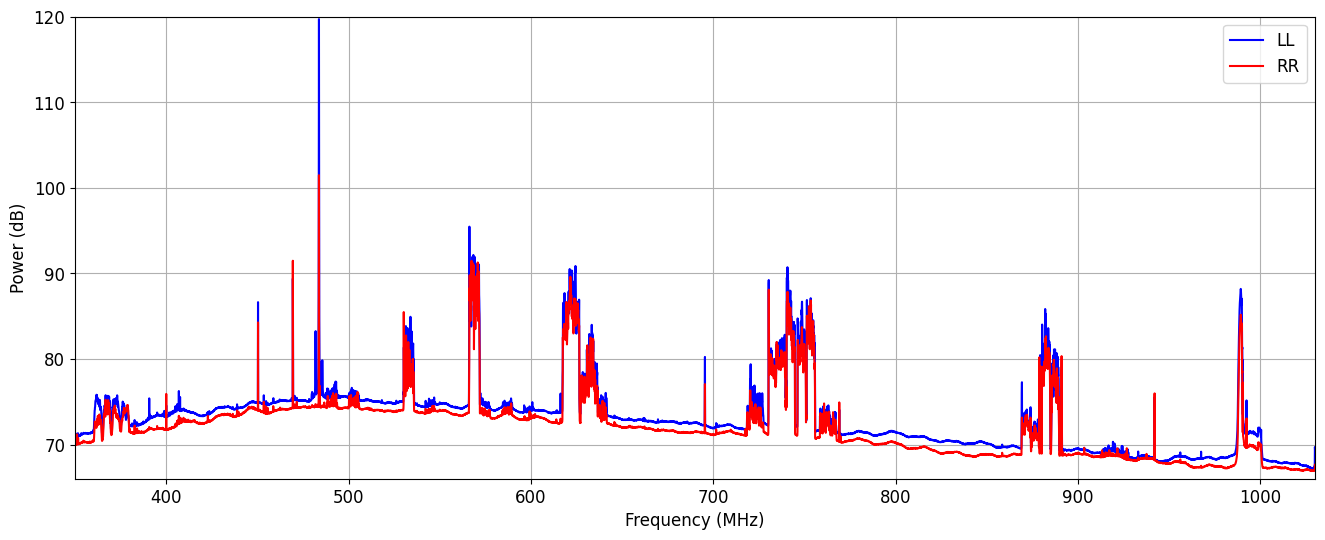

In [41]:
################
time_idx = 1673 # this timestamp is known to contain the satellite emission
################

fs = 12
fig,axs = plt.subplots(1,1,figsize=(16,6)) 
     
data_plot_L = 10*np.log10(LL[time_idx,:])
data_plot_R = 10*np.log10(RR[time_idx,:])
            
axs.plot(freq,data_plot_L, label='LL',color='blue')
axs.plot(freq,data_plot_R, label='RR',color='red')

axs.set_ylim(66,120)
axs.set_xlim(350,1030)
axs.set_xlabel('Frequency (MHz)',fontsize=fs)
axs.tick_params(axis='both',labelsize=fs)
        
axs.set_ylabel('Power (dB)',fontsize=fs)
axs.legend(fontsize=fs,markerscale=5)
axs.grid()

### The time series at two particular frequencies

Text(0.5, 0, 'Time (UTC)')

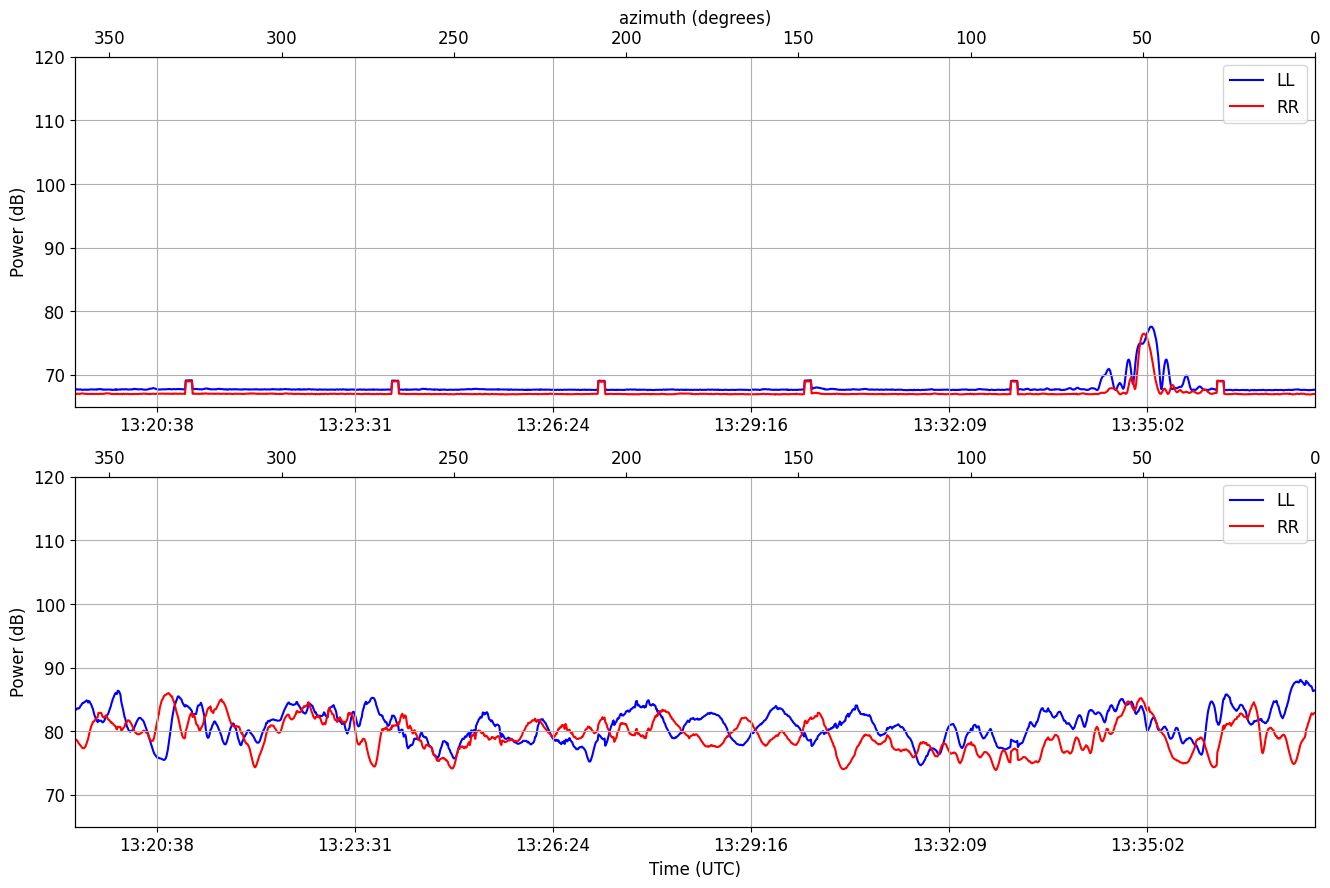

In [51]:
#############
# These frequencies are known to have the satellite signal in them:
fpick1 = 989
fpick2 = 483.8
#fpick1 = 989.42
#fpick2 = 484
#############

fs = 12

freq_idx1 = np.where(abs(freq-fpick1)<df)[0][0]
freq_idx2 = np.where(abs(freq-fpick2)<df)[0][0]

fig,axs = plt.subplots(2,1,figsize=(16,10)) 

axs[0].plot(t_plt, 10*np.log10(LL[:,freq_idx1]), label='LL',color='blue',zorder=1)
axs[0].plot(t_plt, 10*np.log10(RR[:,freq_idx1]), label='RR',color='red',zorder=1)

axs[1].plot(t_plt, 10*np.log10(LL[:,freq_idx2]), label='LL',color='blue',zorder=1)
axs[1].plot(t_plt, 10*np.log10(RR[:,freq_idx2]), label='RR',color='red',zorder=1)

for i in range(0,2):
    axaz = axs[i].twiny()
    axaz.set_xlim(az[0],az[-1])
    axaz.tick_params(axis='x',labelsize=fs)
    axs[i].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
    axs[i].fmt_xdata = mdates.DateFormatter('%H:%M:%S')
    
    # Adjust this to zoom in on different parts of the time series 
    # (or remove to see the whole scan):
    axs[i].set_xlim(t_plt[0],t_plt[-1]) 
    
    axs[i].tick_params(axis='both',labelsize=fs)
    axs[i].set_ylabel('Power (dB)',fontsize=fs)
    axs[i].legend(fontsize=fs,markerscale=5)
    axs[i].grid()
    axs[i].set_ylim(65,120) 
    if i == 0:
        axaz.set_xlabel('azimuth (degrees)',fontsize=fs)
axs[1].set_xlabel('Time (UTC)',fontsize=fs)


## Lists of scans done on different days of the survey
### Read in the file listing azimuth scan IDs, and start/stop times:
#### The scans were NOT done sequentially by their scan IDs; there is some randomness to the order.
#### In order to read in the scans that were done on a particular day, we use the files that have this format:
##### DVAsurvey_phase3_day007.txt

In [ ]:
# Select a day and phase of the survey:
# Phase 1: June/July 2021
# Phase 2: August/September 2022
# Phase 3: December 2022/ January 2023
day = 7
phase = 3
directory = '/srv/data/dva/survey_azimuth_scans/' # This is the directory where the raw scans are stored

In [ ]:
scan_id = []    # The scan id number
scan_start = []  # Start time of the scan (UTC)
scan_stop = []   # Stop time of the scan (UTC)
scan_el = []

# Read in the data and store it in arrays:
with open(directory+'DVAsurvey_phase'+str(phase)+'_day'+f"{day:03}"+'.txt') as fp:
    for line in fp:       
        scan_id.append(int(line.split()[0]))
        scan_start.append(line.split()[1]+'T'+line.split()[2][0:12])
        scan_stop.append(line.split()[3]+'T'+line.split()[4][0:12])
        scan_el.append(line.split()[5][0:2])
        
# Print out the scan numbers with their start and stop times:
for i in range(0,len(scan_id)):
    print(f"{scan_id[i]:04}",scan_start[i],scan_stop[i],scan_el[i])

# Convert start and stop times to Modified Julian Day (MJD).
# This is needed for plotting and for selecting out data collected
# between particular times:
scan_start_mjd = Time(scan_start, format='isot',scale='utc').mjd
scan_stop_mjd  = Time(scan_stop,  format='isot',scale='utc').mjd